# 📚 Book Ratings Insights

What makes readers like a book? We examine this question—which can vary depending on the time and circumstances—in this notebook under six main questions, using the [goodbooks-10k](https://github.com/zygmuntz/goodbooks-10k) dataset, which contains 10,000 popular books from Goodreads and approximately 6 million ratings from readers.

All the logic is contained in the `bookinsights` package: this notebook simply calls the package’s functions and displays the results.

1. **Setup**: Import the package
2. **Data**: Download and load the files
3. **Data cleaning**: Genres, publication periods, authors, and series
4. **Genres** (Question 1)
5. **Publication year** (Question 2)
6. **Popularity** (Question 3)
7. **Series** (Question 4)
8. **Authors** (Question 5)
9. **Readers** (Question 6)

### Research Questions

**Books**

1. Do certain genres consistently receive higher ratings than others?
2. Are older books rated differently from newly released ones?
3. Is popularity the same as appreciation? Do the most-read books receive higher ratings?

**Authors and Series**

4. When a series continues, are the subsequent books in the series rated higher or lower than the first book?
5. How do the ratings an author receives from readers vary across their body of work?

**Readers**

6. How do readers rate books? Are users who rate a large number of books stricter or more consistent than those who read only occasionally?

## 1. Setup

The notebook lives in the `notebooks/` folder, while the `bookinsights` package is
one level up, in the project folder. Python only looks for packages in a few places,
so we add the project folder to that list (`sys.path`).

The `autoreload` extension reloads the modules of the package whenever they change,
without restarting the kernel.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys

# Jupyter runs the notebook from the folder that contains it (notebooks/),
# so the project folder is its parent
PROJECT_ROOT = os.path.dirname(os.getcwd())

# Let Python find the bookinsights package, which lives in the project folder
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

In [3]:
from bookinsights.analysis import (
    author_careers,
    author_spread,
    compare_series_to_first,
    correlate_with_activity,
    correlate_with_rating,
    genre_shares,
    last_main_books,
    rating_shares,
    single_rating_users,
    summarize_by_activity,
    summarize_by_group,
    summarize_by_popularity,
    summarize_careers,
    summarize_series_kinds,
    summarize_series_progression,
    summarize_users,
    test_author_trends,
    test_difference_from_first,
    test_group_differences,
)
from bookinsights.cleaning import clean_books
from bookinsights.data import (
    download_data,
    load_book_tags,
    load_books,
    load_ratings,
    load_tags,
)
from bookinsights.plots import (
    plot_activity_profiles,
    plot_author_careers,
    plot_popularity_vs_rating,
    plot_rating_distribution,
    plot_rating_shares,
    plot_ratings_by_group,
    plot_series_progression,
)

## 2. The data

Data files are not stored in the repository because they are too large for GitHub. The first time it is run, the `download_data()` function downloads the dataset to the `data/` folder; if the files are already there, it does nothing.

In [4]:
paths = download_data()

# relpath shows the paths starting from the project folder, which is shorter to read
{name: os.path.relpath(path, PROJECT_ROOT) for name, path in paths.items()}

{'books.csv': 'data/books.csv',
 'ratings.csv': 'data/ratings.csv',
 'tags.csv': 'data/tags.csv',
 'book_tags.csv': 'data/book_tags.csv'}

The dataset is made of four tables:

- `books`: the metadata of each book (authors, title, year, ratings);
- `ratings`: one row for each rating, from 1 to 5, given by a user to a book;
- `tags`: the names of the tags, i.e. the shelves where users put the books;
- `book_tags`: how many users put each book on each shelf.

Ratings are linked to books through `book_id`, while tags are linked through
`goodreads_book_id`.

In [5]:
books = load_books()
ratings = load_ratings()
tags = load_tags()
book_tags = load_book_tags()

for name, table in [
    ("books", books),
    ("ratings", ratings),
    ("tags", tags),
    ("book_tags", book_tags),
]:
    print(f"{name:<10} {table.shape[0]:>9,} rows  {table.shape[1]:>2} columns")

books         10,000 rows  15 columns
ratings    5,976,479 rows   3 columns
tags          34,252 rows   2 columns
book_tags    999,912 rows   3 columns


In [6]:
books.head()

,book_id,goodreads_book_id,authors,original_publication_year,title,language_code,average_rating,ratings_count,work_ratings_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url
0,1,2767052,Suzanne Collins,2008.0,"The Hunger Games (The Hunger Games, #1)",eng,4.34,4780653,4942365,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...
1,2,3,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Sorcerer's Stone (Harry P...,eng,4.44,4602479,4800065,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...
2,3,41865,Stephenie Meyer,2005.0,"Twilight (Twilight, #1)",en-US,3.57,3866839,3916824,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...
3,4,2657,Harper Lee,1960.0,To Kill a Mockingbird,eng,4.25,3198671,3340896,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...
4,5,4671,F. Scott Fitzgerald,1925.0,The Great Gatsby,eng,3.89,2683664,2773745,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...


The `ratings` table, with approximately 6 million rows, is the largest table in the dataset. The values in this table are small integers. It contains user IDs up to 53,424, book IDs up to 10,000, and ratings ranging from 1 to 5; therefore, `load_ratings` stores these using compact data types instead of the default `int64` type.

In [7]:
print(ratings.dtypes)
print(f"Memory: {ratings.memory_usage(deep=True).sum() / 1e6:.1f} MB")

user_id    int32
book_id    int16
rating      int8
dtype: object
Memory: 41.8 MB


### How are books rated?

The `average_rating` column represents the average of all ratings—ranging from 1 to 5 stars—that Goodreads users have given a book. This is the main variable in the analysis.

In [8]:
books["average_rating"].agg(["mean", "median", "std", "skew"])

mean      4.002191
median    4.020000
std       0.254427
skew     -0.511617
Name: average_rating, dtype: float64

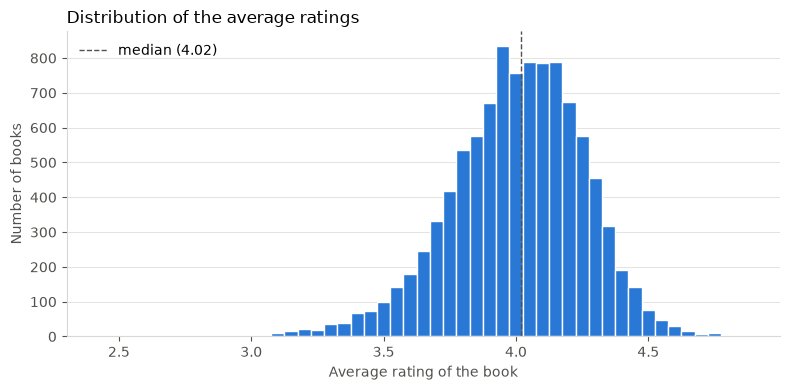

In [9]:
fig = plot_rating_distribution(books)

The ratings are concentrated in a narrow range: 95% of the books have an average
between 3.5 and 4.5 stars, and the standard deviation is only 0.25. A difference of
0.1 stars between two groups of books is therefore not negligible.

The distribution is not symmetric: it has a longer tail on the left (skewness
$-0.51$), made of the few books that readers did not like. This is why, in the
following sections, we compare groups with tests that do not assume normal data.

## 3. Cleaning

`clean_books` creates the table used in the analysis. The main choices are as follows:

- **Genres.** Tags reflect users’ bookshelves, and most of them are not genres (such as `to-read`, `favorites`, `owned`, etc.). By merging synonyms (e.g., `sci-fi` and `science-fiction`), we maintain a list of 18 genres and assign each book its **primary genre**: the genre tag used by the most users. The terms `young-adult` and `children` define a target audience, but since Goodreads uses them as genres—and these values serve as an evaluation criterion for a new generation of readers—they are retained in the list. Rows with negative counts (6) and duplicate rows (8) are removed from the tags.
- **Publication periods.** Years are divided into six periods; older books (those with negative years, e.g., the *Epic of Gilgamesh*) fall into the “before 1800” category.
- **Primary author.** Some records were found where the “author” field included multiple names, including translators. If a book lists multiple names, the first name is considered the author. Accordingly, other names in the record were generally treated as illustrators, translators, or narrators and were not included in the main analysis.
- **Series.** The series title and the volume number within the series are extracted from the title, e.g., *(The Hunger Games, #1)*. Records that collect several books of a series in one volume, referred to as a “set” (e.g., *#1–7*), are not single books, so they are not assigned to a series.

In [10]:
clean = clean_books(books, book_tags, tags)
clean[
    [
        "title",
        "main_author",
        "publication_year",
        "era",
        "series",
        "series_number",
        "genre",
    ]
].head(10)

,title,main_author,publication_year,era,series,series_number,genre
0,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,2008,2000-2009,The Hunger Games,1.0,young-adult
1,Harry Potter and the Sorcerer's Stone (Harry P...,J.K. Rowling,1997,1950-1999,Harry Potter,1.0,fantasy
2,"Twilight (Twilight, #1)",Stephenie Meyer,2005,2000-2009,Twilight,1.0,young-adult
3,To Kill a Mockingbird,Harper Lee,1960,1950-1999,NaN,NaN,classics
4,The Great Gatsby,F. Scott Fitzgerald,1925,1900-1949,NaN,NaN,classics
5,The Fault in Our Stars,John Green,2012,2010 or later,NaN,NaN,young-adult
6,The Hobbit,J.R.R. Tolkien,1937,1900-1949,NaN,NaN,fantasy
7,The Catcher in the Rye,J.D. Salinger,1951,1950-1999,NaN,NaN,classics
8,"Angels & Demons (Robert Langdon, #1)",Dan Brown,2000,2000-2009,Robert Langdon,1.0,mystery
9,Pride and Prejudice,Jane Austen,1813,1800-1899,NaN,NaN,classics


How many books fall into each genre? A few books (cookbooks, religious books, ...)
have no tag of the list, so they have no genre.

In [11]:
clean["genre"].value_counts(dropna=False)

genre
fantasy               1230
young-adult           1116
romance               1086
mystery               1060
historical-fiction     796
classics               767
biography              584
children               555
science-fiction        476
comics                 394
thriller               306
self-help              298
history                288
horror                 260
humor                  231
philosophy             222
literary-fiction       222
poetry                  64
NaN                     45
Name: count, dtype: int64

Most of the books were published after 1950: the older books are those we now call classics, the ones that are still read today.

In [12]:
clean["era"].value_counts(sort=False, dropna=False)

era
before 1800       125
1800-1899         254
1900-1949         466
1950-1999        2946
2000-2009        3121
2010 or later    3067
NaN                21
Name: count, dtype: int64

The series with the largest number of books in the dataset:

In [13]:
clean["series"].value_counts().head(10)

series
In Death                       41
Discworld                      39
Stephanie Plum                 27
Hercule Poirot                 25
Kinsey Millhone                24
Alex Cross                     23
Jack Reacher                   23
Kay Scarpetta                  23
Anita Blake, Vampire Hunter    23
Harry Bosch                    21
Name: count, dtype: int64

## 4. Do certain genres consistently receive higher ratings than others?

Each book is one observation, described by its `average_rating`: this way every book
counts the same, whatever its number of ratings. The 45 books without a genre are left
out.

In [14]:
summarize_by_group(clean, "genre").round(3)

,n_books,mean,median,std,weighted_mean
genre,,,,,
comics,394,4.224,4.230,0.213,4.246
poetry,64,4.166,4.215,0.232,4.200
children,555,4.140,4.160,0.175,4.174
fantasy,1230,4.098,4.115,0.239,4.197
romance,1086,4.012,4.060,0.279,4.004
history,288,4.040,4.055,0.220,4.042
philosophy,222,4.003,4.030,0.225,3.992
self-help,298,4.026,4.025,0.194,3.991
biography,584,3.985,4.000,0.232,3.977


Comic books, poetry, and children’s books are at the top, while literary fiction, humor, and horror are at the bottom. The difference between the first and last genres is approximately 0.5 stars. This may seem small; however, the standard deviation for all books is only 0.25, so the gap is about two standard deviations.

The `weighted_mean` column counts each book as many times as the number of ratings it received; in other words, it is the average of the individual ratings. The ranking follows a similar pattern: the most notable exceptions are the fantasy and historical fiction genres, which rise in the rankings because their most popular books (such as *Harry Potter* and *The Help*) also receive very high ratings.

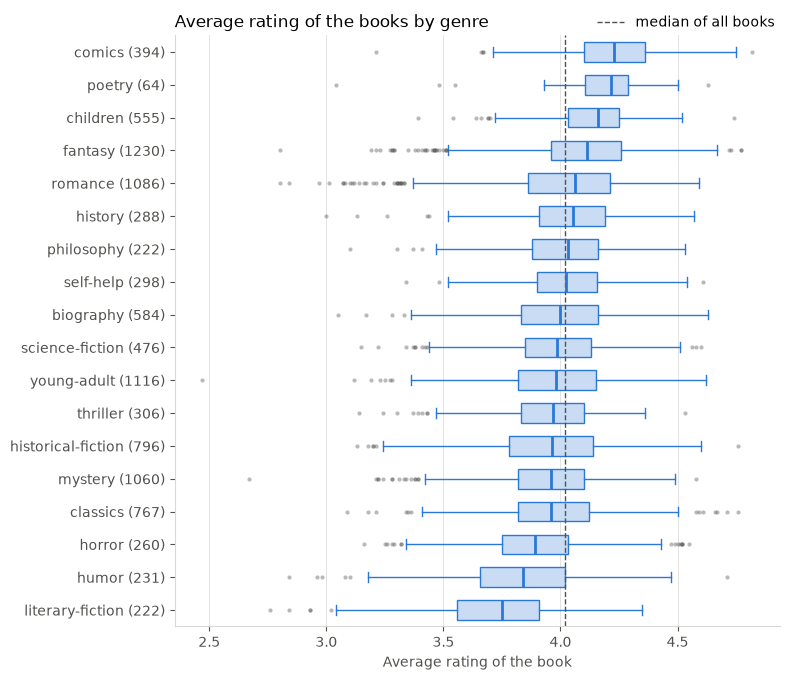

In [15]:
fig = plot_ratings_by_group(clean, "genre")

The boxes show that the differences are not only in the averages: the whole
distribution of comics and children's books is shifted to the right, and the boxes of
the first and the last genres do not even overlap. Each genre still has a wide spread,
though: the best literary novels (e.g. *Small Great Things*, 4.35) are rated higher
than a typical comic, even if they are only about 2% of their genre.

### Is the difference significant?

To compare 18 groups we could use the one-way ANOVA, but it assumes normal groups with
equal variances, and neither holds here: the ratings are skewed to the left and the
spread changes from genre to genre (e.g. the standard deviation goes from 0.18 for
children's books to 0.30 for humor). We use the **Kruskal-Wallis** test instead,
which compares the ranks of the ratings and makes no assumption on their distribution.

- $H_0$: the ratings of all the genres come from the same distribution;
- $H_1$: at least one genre tends to be rated differently.

With almost 10,000 books even a tiny difference would be significant, so we also
compute an effect size, the **epsilon squared**
$\varepsilon^2 = \frac{H - k + 1}{n - k}$, where $k$ is the number of genres and $n$
the number of books.

In [16]:
test_group_differences(clean, "genre")

{'statistic': 1261.5216864803256,
 'p_value': 8.337277685931834e-258,
 'epsilon_squared': 0.12524118813327217,
 'n_books': 9955,
 'n_groups': 18}

The p-value is practically zero, so we reject $H_0$: the genres are not rated
the same. The effect size $\varepsilon^2 \approx 0.13$ means that the genre explains
about 13% of the variability of the ranks, a **moderate** effect.

**Answer.** Yes: some genres are consistently rated higher. Comics, poetry, children's
books and fantasy are rated above the other genres, literary fiction, humor and horror
below. Still, the genre explains only a part of the rating: most of the differences
are between the books of the same genre.

## 5. Are older books rated differently from newly released ones?

We look at the publication year in two ways: grouped into eras, to compare the
distributions as we did for the genres, and as a number, to look for a trend. The 21
books without a publication year are left out.

In [17]:
summarize_by_group(clean, "era", sort_by_median=False).round(3)

,n_books,mean,median,std,weighted_mean
era,,,,,
before 1800,125,3.906,3.88,0.241,3.847
1800-1899,254,3.958,3.97,0.213,3.965
1900-1949,466,4.033,4.06,0.216,4.037
1950-1999,2946,4.034,4.05,0.221,4.073
2000-2009,3121,3.977,3.99,0.265,4.011
2010 or later,3067,3.999,4.02,0.277,4.042


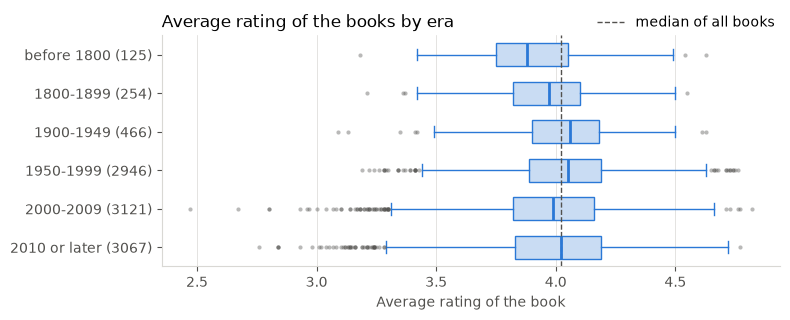

In [18]:
fig = plot_ratings_by_group(clean, "era", sort_by_median=False)

In [19]:
test_group_differences(clean, "era")

{'statistic': 106.87627864463084,
 'p_value': 1.872338225032078e-21,
 'epsilon_squared': 0.010215208928570224,
 'n_books': 9979,
 'n_groups': 6}

The differences between the eras are statistically significant, but very small:
$\varepsilon^2 \approx 0.01$, i.e. the era explains about 1% of the variability of
the ranks, ten times less than the genre. The pattern is not a trend either: the books
of the 20th century are the best rated, those before 1800 the worst, and recent books
are in between.

The **Spearman correlation** between the publication year and the rating confirms that
there is no trend. Like the Kruskal-Wallis test, it works on ranks, so it does not
assume a linear relation and it is not affected by the very old books (down to 1750
BC).

In [20]:
correlate_with_rating(clean, "publication_year")

{'rho': -0.027013626482248032,
 'p_value': 0.006961526322057463,
 'n_books': 9979}

$\rho \approx -0.03$: practically no relation, even though the p-value is
below 0.05. Again, with 10,000 books a p-value alone says little.

### A selection effect

The dataset contains the 10,000 most popular books on Goodreads, so the old books in it
are not a random sample of old books: they are the ones still read today, mostly
classics. The share of each genre in each era shows it:

In [21]:
genre_shares(clean, "era")[["classics", "fantasy", "young-adult", "romance"]].round(2)

genre,classics,fantasy,young-adult,romance
era,,,,
before 1800,0.58,0.01,0.00,0.00
1800-1899,0.78,0.00,0.00,0.01
1900-1949,0.47,0.01,0.01,0.00
1950-1999,0.09,0.12,0.04,0.05
2000-2009,0.00,0.15,0.13,0.11
2010 or later,0.00,0.12,0.20,0.19


Most books published before 1950 are “classics,” a genre that scores below average. These books are often read not out of personal interest, but because they are assigned as homework or projects in school. However, there are no books among those published recently that could be considered classics. If we exclude the classics, the oldest books no longer rank among those with the lowest scores:

In [22]:
not_classics = clean[clean["genre"] != "classics"]
summarize_by_group(not_classics, "era", sort_by_median=False)[["n_books", "median"]]

,n_books,median
era,,
before 1800,52,3.970
1800-1899,56,4.075
1900-1949,247,4.090
1950-1999,2683,4.050
2000-2009,3109,3.990
2010 or later,3066,4.020


**Answer.** Not really. The era explains only about 1% of the differences in
rating, and there is no trend over the years. The slightly lower ratings of the oldest
books depend on their genre: they are mostly classics, and without the classics they
are rated like the others.

## 6. Is popularity the same as appreciation?

We measure a book’s popularity using the `work_ratings_count` value, which represents the total number of ratings received by all its editions. This distribution is extremely skewed: While the median book has approximately 24,000 ratings, the most-rated book has nearly 5 million (the mean, pulled up by a few very popular books, is about 60,000). For this reason, we use Spearman’s correlation based on the rankings and a logarithmic axis on the graph.

In [23]:
correlate_with_rating(clean, "work_ratings_count")

{'rho': 0.06522809347356445,
 'p_value': 6.623353542909254e-11,
 'n_books': 10000}

$\rho \approx 0.07$: the most rated books are not rated noticeably higher. To see
the whole picture, we split the books into ten groups of the same size by number of
ratings, from the 10% least rated books (group 1) to the 10% most rated ones
(group 10).

In [24]:
summarize_by_popularity(clean).round(3)

,n_books,min_ratings_count,median_ratings_count,median,min,std
popularity_group,,,,,,
1,1000,5510,10880.0,4.000,2.76,0.288
2,1000,12063,13180.5,3.990,2.80,0.266
3,1001,14228,15439.0,3.990,3.02,0.255
4,999,16707,18112.0,4.030,2.93,0.252
5,1000,19744,21565.5,4.010,2.80,0.257
6,1000,23834,26266.5,4.040,2.84,0.242
7,1000,29331,33440.0,4.040,2.67,0.242
8,1000,38782,45916.0,4.025,2.47,0.255
9,1000,55675,72524.0,4.040,3.07,0.243


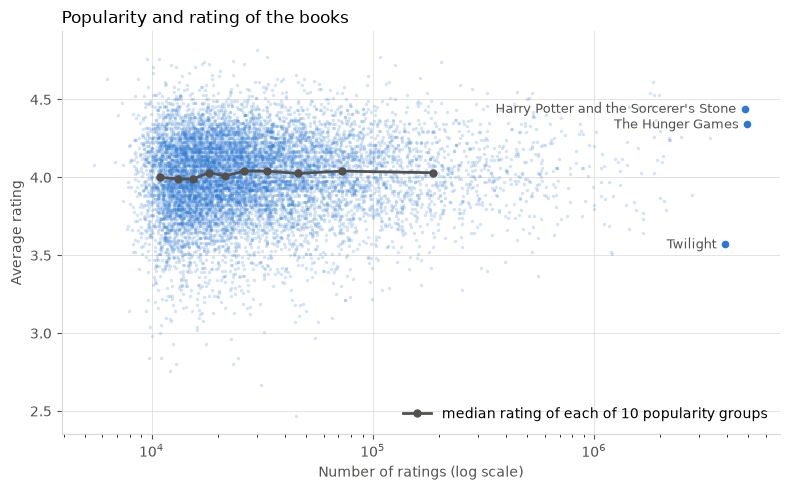

In [25]:
fig = plot_popularity_vs_rating(clean)

The line of medians is nearly flat: ranging from 4.00 in the least popular group to 4.03 in the most popular group. However, popularity shifts the distribution of ratings: the most popular books never receive truly poor ratings (while the lowest rating in the 10th group is 3.28, in the other groups this figure ranges from 2.5 to 3.1). This is likely because books that readers don’t like are no longer recommended or read. Still, being read by millions does not guarantee a high rating. For example, *Twilight*, one of the most popular books of its time, is among the three most-rated books, yet its average rating is just 3.57.

It’s important to remember that all books in the dataset are popular (with at least 5,500 ratings); therefore, we can say that we are comparing popular and very popular books. Books read by only a very small audience are not included here.

**Answer.** No—popularity and appreciation are different metrics. The number of ratings has almost no correlation with the average rating. The most popular books simply avoid receiving the lowest ratings.

## 7. What happens as a series goes on?

We compare each book in a series to the **first book in that same series**: we examine the difference in scores and the number of ratings that book received relative to those of the first book. Comparing books within the same series eliminates differences between series. It’s important to remember that some series are better than others.

- A series is identified by its title *and* author, since different authors may use the same series title (for example, there are two series titled *The Secret*).
- We consider series that have the first book in the data and at least three main books.
- Novellas and prequels (e.g., *#1.5* or *#0*) are kept apart from the main books: they are too short to be considered main books, or they describe other events within the book’s universe, so they are treated as a separate group and addressed at the end of this section.

For example, the *Harry Potter* series:

In [26]:
series = compare_series_to_first(clean)
series.loc[
    series["series"] == "Harry Potter",
    ["title", "series_number", "average_rating", "rating_diff", "ratings_ratio"],
].round(2)

,title,series_number,average_rating,rating_diff,ratings_ratio
1,Harry Potter and the Sorcerer's Stone (Harry P...,1.0,4.44,0.00,1.00
22,Harry Potter and the Chamber of Secrets (Harry...,2.0,4.37,-0.07,0.40
17,Harry Potter and the Prisoner of Azkaban (Harr...,3.0,4.53,0.09,0.41
23,Harry Potter and the Goblet of Fire (Harry Pot...,4.0,4.53,0.09,0.39
20,Harry Potter and the Order of the Phoenix (Har...,5.0,4.46,0.02,0.38
26,Harry Potter and the Half-Blood Prince (Harry ...,6.0,4.54,0.10,0.37
24,Harry Potter and the Deathly Hallows (Harry Po...,7.0,4.61,0.17,0.38


The last book is rated 0.17 stars higher than the first one, but it received only
38% of its ratings. Is this true for the series in general?

In [27]:
progression = summarize_series_progression(series)
progression.round(3)

,n_series,median_rating_diff,share_higher,median_ratings_ratio
position,,,,
1,538,0.000,0.000,1.000
2,525,0.090,0.724,0.574
3,522,0.100,0.741,0.476
4,279,0.120,0.742,0.407
5,184,0.130,0.788,0.365
6,140,0.135,0.779,0.353
7,98,0.120,0.755,0.326
8,74,0.100,0.703,0.289
9,60,0.150,0.783,0.313


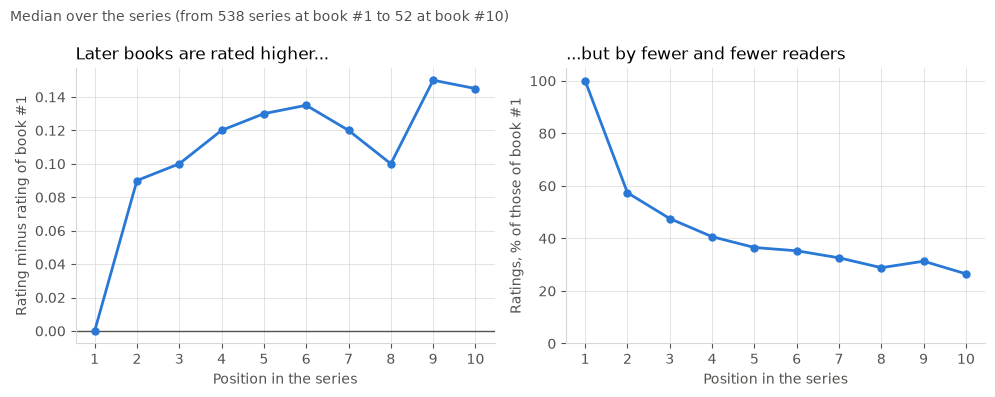

In [28]:
fig = plot_series_progression(progression)

Two opposite trends stand out:

- **Ratings go up.** The second book is already rated 0.09 stars higher than the first one (median), and about three books out of four are rated higher than the first book of their series.
- **Readers go down.** As the series goes on, fewer and fewer readers rate the books: the second book receives about half the ratings of the first one, the tenth about a quarter.

These two trends are probably two sides of the same phenomenon: **self-selection**. Readers who did not like the first book do not read the following ones. The later books are rated only by readers who are loyal to the series or to the author, and these fans rate generously. So the higher ratings do not mean that the later books are better.

### Is the difference significant?

For each series, we compare its last main book with its first book. The data are **paired** (each book is compared with the first book of its own series), so we use the **Wilcoxon signed-rank test**, which tests whether the differences are centered on zero without assuming that they are normal.

- $H_0$: the last book is rated like the first one (median difference 0);
- $H_1$: it is rated differently.

In [29]:
test_difference_from_first(last_main_books(series)["rating_diff"])

{'n_books': 538,
 'median_diff': 0.1200000000000001,
 'share_higher': 0.7304832713754646,
 'statistic': 29885.5,
 'p_value': 6.590581965949831e-31}

The last main book received a rating 0.12 stars higher than the first book (median), and the p-value is practically zero: this increase is systematic.

### Novellas and Prequels

Novellas and prequels are typically read by fans of a series. Some readers skip these books and move on to the main books in the series because these novellas and prequels are often regarded as books that merely fill in some gaps in the story without affecting the main plot. How do they compare to the first book?

In [30]:
summarize_series_kinds(series).round(3)

,n_books,n_series,median_rating_diff,share_higher,median_ratings_ratio
kind,,,,,
main,2232,538,0.10,0.728,0.416
in-between,70,43,-0.05,0.429,0.093


In [31]:
in_between = series[series["kind"] == "in-between"]
test_difference_from_first(in_between["rating_diff"])

{'n_books': 70,
 'median_diff': -0.04999999999999982,
 'share_higher': 0.42857142857142855,
 'statistic': 913.5,
 'p_value': 0.1127973831747793}

In [32]:
in_between.nlargest(5, "work_ratings_count")[
    ["title", "average_rating", "rating_diff", "ratings_ratio"]
].round(2)

,title,average_rating,rating_diff,ratings_ratio
431,"I, Robot (Robot #0.1)",4.17,0.03,3.62
731,The Short Second Life of Bree Tanner: An Eclip...,3.51,-0.06,0.04
833,"Midnight Sun (Twilight, #1.5)",4.03,0.46,0.04
945,"The Kill Order (Maze Runner, #0.5)",3.69,-0.33,0.14
1196,Free Four: Tobias Tells the Divergent Knife-Th...,4.18,-0.06,0.04


Novellas and prequels are read by an even smaller group: they receive only about
9% of the ratings of the first book, so only the most devoted fans rate them. If
self-selection were the whole story, they should be the best rated books of the series.
They are not: their median rating is slightly *lower* than that of the first book, and
only 43% of them are rated higher (the difference is not significant, p ≈ 0.11). Fans
seem to appreciate them as extras, but not as much as the main novels.

**Answer.** As a series goes on, its books are rated higher but by fewer readers: the
last book is rated about 0.12 stars higher than the first one, with a fraction of its
readers. This is mostly self-selection: only the readers who liked the beginning keep
reading. Novellas and prequels, read only by the most devoted fans, do not follow this
pattern.

## 8. How do the ratings of an author evolve across their works?

We keep the authors with at least five books in the data, and order the books of each
author by publication year. Note that the data contain only popular books, so the first
book of an author here is not necessarily their debut.

### How consistent are the authors?

Before looking at trends, how much do the books of the same author differ? We can treat
each author as a group and reuse the Kruskal-Wallis test of the genres.

In [33]:
careers = author_careers(clean)
test_group_differences(careers, "main_author")

{'statistic': 3095.544984815407,
 'p_value': 0.0,
 'epsilon_squared': 0.5778390543406885,
 'n_books': 5014,
 'n_groups': 472}

In [34]:
author_spread(careers)

{'median_author_std': 0.1341986013670443, 'overall_std': 0.2527730564292543}

The authors are very consistent: the author explains about 58% of the variability
of the ranks ($\varepsilon^2 \approx 0.58$), against 13% for the genre. The books of a
typical author differ by 0.13 stars (standard deviation), half the spread of all the
books. To guess the rating of a book, its author is far more informative than its
genre.

### Do the ratings go up or down along a career?

For each book, we compute the difference between its rating and the mean rating of its
author, and summarize it by position in the career. We do it twice: with all the books,
and with the **standalone books only**, since we saw in the previous section that the
later books of a series are rated higher because of self-selection.

In [35]:
standalone = author_careers(clean, standalone_only=True)
career_all = summarize_careers(careers)
career_standalone = summarize_careers(standalone)
career_all.join(career_standalone, suffixes=("_all", "_standalone")).round(3)

,n_authors_all,median_deviation_all,share_above_all,n_authors_standalone,median_deviation_standalone,share_above_standalone
position,,,,,,
1,472,-0.045,0.375,207,0.026,0.575
2,472,0.009,0.519,207,0.030,0.599
3,472,0.023,0.589,207,0.019,0.570
4,472,0.020,0.576,207,0.006,0.512
5,472,0.024,0.561,207,-0.003,0.488
6,374,0.026,0.612,151,-0.005,0.477
7,296,0.037,0.615,107,-0.012,0.477
8,237,0.008,0.506,82,-0.021,0.463
9,206,0.008,0.510,63,-0.008,0.492


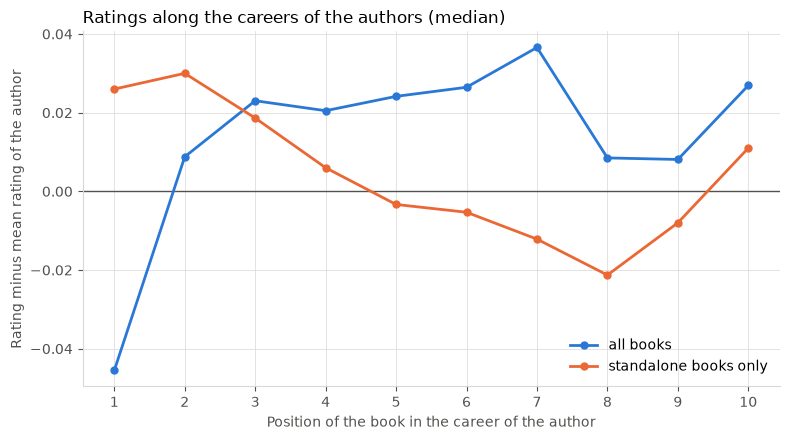

In [36]:
fig = plot_author_careers(career_all, career_standalone)

The two lines tell opposite stories:

- **All books:** the first book is the worst rated (0.05 stars below the mean of its
  author), the following ones are slightly above the mean. Authors seem to improve.
- **Standalone books only:** the first books are the best rated, and the ratings slowly
  go down until the eighth book. Authors seem to decline.

The apparent improvement comes from the series: many authors start with the first book
of a series, and its sequels, read only by the fans, are rated higher.

To test the trend, we compute for each author the Spearman correlation between
publication year and rating (positive: later books are rated higher), and check with the
Wilcoxon signed-rank test whether these correlations are centered on zero.

In [37]:
test_author_trends(careers)

{'n_authors': 472,
 'median_rho': 0.03904873127809647,
 'share_positive': 0.5190677966101694,
 'statistic': 48852.0,
 'p_value': 0.04734128837929497}

In [38]:
test_author_trends(standalone)

{'n_authors': 207,
 'median_rho': -0.198316555189459,
 'share_positive': 0.357487922705314,
 'statistic': 6980.5,
 'p_value': 2.5957311417608188e-05}

With all the books, the typical correlation is close to zero ($\rho \approx 0.04$,
p ≈ 0.05): no clear trend. With the standalone books, the correlation is negative for
most authors (median $\rho \approx -0.20$, only 36% of the authors have a positive
trend) and the result is significant (p ≈ 0.00003): the later standalone books of an
author tend to be rated lower. A possible explanation is, again, selection: an author
usually becomes popular thanks to an excellent book, and the following ones are read
because of that success, with higher expectations.

Still, the changes along a career are small (a few hundredths of a star) compared with
the differences between authors.

**Answer.** The ratings of an author are remarkably stable: the author explains more of
the rating than any other variable we looked at. Across their works, standalone books
tend to be rated slightly lower over time, while the sequels of a series are rated
higher; mixing the two hides the decline.

## 9. How do readers rate books?

So far each book was described by its average rating. Here we use the `ratings` table,
with the single ratings given by the users, from 1 to 5 stars.

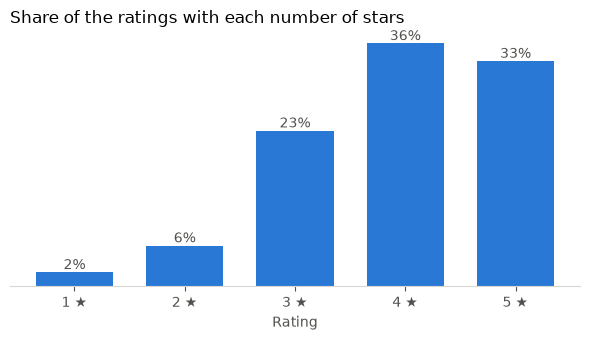

In [39]:
fig = plot_rating_shares(rating_shares(ratings))

Readers are generous: about 70% of the ratings are 4 or 5 stars, and only 8% are
1 or 2 stars. This is not surprising, since people mostly read books they expect to
like.

### Users who rate many books vs the others

For each user we compute:

- the number of ratings, the mean rating and the share of 5-star ratings;
- the **relative harshness**: the mean difference between their ratings and the average
  ratings of the same books. Unlike the mean rating, it does not depend on which books
  the user chose: a negative value means that the user rates lower than the other
  readers of the same books;
- two measures of **consistency**: the standard deviation of their ratings (do they
  always give similar ratings, or use the whole scale?) and the **distance from the
  other readers**, i.e. the mean absolute difference from the average ratings of the
  books (do they agree with the others?).

In [40]:
users = summarize_users(ratings, clean)
users["n_ratings"].describe()

count    53424.000000
mean       111.868804
std         26.071224
min         19.000000
25%         96.000000
50%        111.000000
75%        128.000000
max        200.000000
Name: n_ratings, dtype: float64

An important limitation: every user in the dataset has rated **at least 19
books** (the median is 111), probably because the dataset was built from active users.
So we cannot study really occasional readers: we compare active and very active
readers.

We split the users into five groups of the same size by their number of ratings:

In [41]:
summarize_by_activity(users).round(3)

,n_users,min_ratings,max_ratings,mean_rating,share_five,relative_harshness,std_rating,crowd_distance
activity_group,,,,,,,,
1,10910,19,92,4.000,0.337,-0.030,0.850,0.744
2,10821,93,105,3.941,0.301,-0.080,0.855,0.732
3,10947,106,117,3.914,0.291,-0.102,0.864,0.735
4,10510,118,133,3.893,0.286,-0.119,0.868,0.737
5,10236,134,200,3.857,0.267,-0.150,0.870,0.744


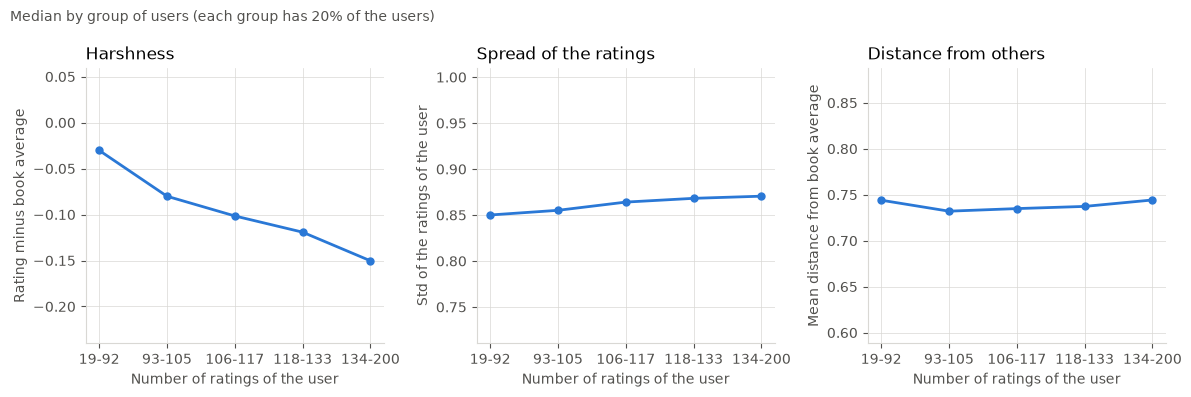

In [42]:
fig = plot_activity_profiles(summarize_by_activity(users))

The number of ratings is a number, so we measure its relation with each measure by
the **Spearman correlation**:

In [43]:
correlate_with_activity(users).round(4)

,rho,p_value
mean_rating,-0.0991,0.0000
share_five,-0.0990,0.0000
relative_harshness,-0.0861,0.0000
std_rating,0.0339,0.0000
crowd_distance,0.0034,0.4351


- **Harshness: yes, slightly.** The users with more ratings give lower ratings (the
  median mean rating goes from 4.00 to 3.86) and fewer 5-star ratings (from 34% to
  27%). The relative harshness shows that this is not only a matter of which books
  they read: they rate the *same* books lower than the other readers (from -0.03 to
  -0.15 stars). The correlations are significant but weak ($\rho \approx -0.1$).
- **Consistency: no.** The spread of the ratings is practically the same in all the
  groups (0.85-0.87, $\rho \approx 0.03$), and so is the distance from the other
  readers ($\rho \approx 0.003$, not significant): users who rate many books are
  neither more regular nor more in agreement with the crowd.

Some users are extremely consistent, though: a few hundred users gave the same rating
to all their books, almost always 5 stars.

In [44]:
single_rating_users(users)

mean_rating
1      4
3      1
4     19
5    266
Name: count, dtype: int64

**Answer.** Readers who rate many books are slightly harsher: they give fewer 5
stars and rate the same books lower than the others. But they are not more consistent:
the spread of their ratings and their agreement with the other readers do not change
with the number of ratings. Keep in mind that all the users of the dataset are active
readers.